# Welcome to the UGA-WRF Club MPAS Tutorial Visualization Guide!
By the end of the guide, you should:
- Have a better understanding of how MPAS' meshes work
- Have a starting ground for plotting your modeling output
- If not already, understand Python virtual environments and Anaconda better and why we like to use it

If you haven't already, go install Anaconda (see here: https://www.anaconda.com/docs/getting-started/miniconda/install/windows-cli-install). Open an Anaconda prompt and create a new environment and activate it (see here: https://docs.conda.io/projects/conda/en/latest/user-guide/tasks/manage-environments.html).

## Step one: import the modules and files you need
Modules are bits of pre-written code made by you or (more frequently) written by other people to avoid the headache of having to write a bunch of code yourself.

Most modules do not come pre-installed with Python; so we'll have to install them ourselves.

A more mathy analogy: Modules are like skipping the derivation of a proven math equation; you don't need to know *how* to make a map from first prinicples in Python, it's already written for you by someone else who put it in the Cartopy module!

Another developer already did the heavy lifting of figuring out the logic and code needed to create the map; you simply just `import` that logic and code.

In [1]:
# In your Anaconda prompt, make sure you have these packages: 
# uxarray numpy matplotlib cartopy metpy scipy ipykernel
# These modules are stored in the `conda-forge` channel!
# Documentation: https://www.anaconda.com/docs/getting-started/working-with-conda/packages/install-packages
import uxarray as ux
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from metpy.plots import USCOUNTIES

In [2]:
# Grab these from your completed model run
# If you did not run the model, instead look at the 'examples' folder
mesh_file = 'athens.grid.nc'
diag_file = 'diag.2026-10-01_12.00.00.nc'  # replace with your output file

uxds = ux.open_dataset(mesh_file, diag_file)

print("Faces (cells):", uxds.uxgrid.n_face)
print("Sample of variables:", list(uxds.data_vars.keys())[:15])

Faces (cells): 2049
Sample of variables: ['initial_time', 'xtime', 'mslp', 'relhum_50hPa', 'relhum_100hPa', 'relhum_200hPa', 'relhum_250hPa', 'relhum_500hPa', 'relhum_700hPa', 'relhum_850hPa', 'relhum_925hPa', 'dewpoint_50hPa', 'dewpoint_100hPa', 'dewpoint_200hPa', 'dewpoint_250hPa']


## Step 2: Choosing what to visualize
MPAS comes with a whole heck of a lot of diagnostics that it computes to give you a good idea of how it simulated the atmosphere!

In this step, there's a couple of them partially for you: 't2m' (temperature at 2 meters), 'q2' (mixing ratio at 2 meters), 'mslp' (mean sea-level pressure), 'wspd' (wind speed at lowest level), and 'rainncv' (total rain from both non-convective and convective schemes)

What we need to figure out:
- Unit conversions
- Labels
- Setting a color map and bounds

See colormaps: https://matplotlib.org/stable/users/explain/colors/colormaps.html

In [3]:
# --- STEP 2: CHOOSE YOUR VARIABLE ---
# Options to try: 't2m', 'q2', 'mslp', 'wspd', 'total_precip'
# See https://www2.mmm.ucar.edu/projects/mpas/site/documentation/users_guide/appD_fields.html for more options!
variable_choice = 'wspd'

if variable_choice == 'wspd':
    # Below, the variable is pulled out for you: the format is uxds['variable'] where variable is the field name as shown in the user's guide. So, 'u10' corresponds to '10-meter zonal wind'.
    # Could be a helpful hint for the challenge (nudge nudge)
    u10 = uxds['u10'].isel(Time=0)
    v10 = uxds['v10'].isel(Time=0)
    # Do you remember how to derive wind speed given u and v? Hint: Pythagorean theorem!
    # In Python, ** is equal to ^ (raising a number to a power)
    wspd = (u10**2 + v10**2)**0.5
    # Conversion: m/s -> kts is speed_m/s * 1.944
    data = wspd * 1.94384
    # We actually need a label for our plot title and colorbar! What are we plotting, with units?
    var_label = "10m Wind Speed (kts)"
    cmap = "YlOrRd"
    # We use np.arange(min, max, step) to make an array of numbers starting from 'min', going to 'max', split every 'step'
    # for example: 0, 50, 5 will make an array that goes from 0-50 with a step of 5 (0, 5, 10, 15, 20... 45, 50)
    # This will correspond to our color map: the left end of the colormap would be assigned to 0, the right end to 50, and a different color would be used every 5 units
    levels = np.arange(0, 55, 5)

elif variable_choice == 't2m':
    # Conversion: K -> C is temp_K - 273.15
    # Conversion: C -> F is temp_C * 9/5 + 32
    data = (uxds['t2m'].isel(Time=0) - 273.15) * 9/5 + 32
    var_label = "2m Temperature (°F)"
    cmap = "coolwarm"
    levels = np.arange(20, 105, 5)

elif variable_choice == 'mslp':
    # Conversion: Pa -> hPa is pressure_pa / 100
    data = uxds['surface_pressure'].isel(Time=0) / 100.0
    var_label = "Surface Pressure (hPa)"
    cmap = "viridis"
    levels = np.arange(980, 1035, 4)

elif variable_choice == 'total_precip':
    # Conversion: mm to inches in rain_mm / 25.4
    rainc = np.nan_to_num(uxds['rainc'].isel(Time=0).values)
    rainnc = np.nan_to_num(uxds['rainnc'].isel(Time=0).values)
    data = (rainc + rainnc) / 25.4
    var_label = "Total Accumulated Precipitation (in)"
    cmap = 'Greens'
    levels = [0.0,0.01,0.1,0.25,0.5,0.75,1,1.25,1.50,1.75,2,2.5,3,4,5,7,10,15,20]

print(data)

<xarray.UxDataArray (n_face: 2049)> Size: 8kB
array([ 5.9279695, 16.671843 ,  8.823915 , ...,  4.0933595, 11.147499 ,
       11.5489645], shape=(2049,), dtype=float32)
Coordinates:
    Time     datetime64[ns] 8B 2026-10-01T12:00:00
Dimensions without coordinates: n_face
Attributes:
    units:    m s^{-1}


### Challenge: Choose a variable from the user's guide to plot that looks neat to you, complete with a nice color map and values!

Consult https://www2.mmm.ucar.edu/projects/mpas/site/documentation/users_guide/appD_fields.html for fields.

You will have to make a new 'else if' statement in the chain where variable choice == the one you want to plot.

## Step 3: Prepping the map

In [4]:
# Define region of interest [lon_min, lon_max, lat_min, lat_max]
extent = [-92.0, -75.0, 28.0, 39.0]  # Southeast US

# Extract cell coordinates
lon_centers = uxds.uxgrid.face_lon.values
lat_centers = uxds.uxgrid.face_lat.values
mask = (
    (lon_centers >= extent[0] - 2) & (lon_centers <= extent[1] + 2) &
    (lat_centers >= extent[2] - 2) & (lat_centers <= extent[3] + 2)
)

valid_time_str = uxds["xtime"].isel(Time=0).values.item().decode().strip()

sub_lon = lon_centers[mask]
sub_lat = lat_centers[mask]
sub_data = (data.values if hasattr(data, 'values') else data)[mask]

### Challenge: Make a further refined map using a new set of coordinates!

With Google Maps or OpenStreetMap, you can find coordinates for ANY place on Earth.

In the simulation we ran (and the provided example files), we have a domain that includes a lot of the Southeast, Mid-Atlantic, and Great Lakes, so you have a lot to play with.

https://google.com/maps (right click to reveal coordinates)

https://www.openstreetmap.org (right click -> 'show address' to reveal coordinates)

## Step 4: Creating the map!

c:\Users\mbc18672\AppData\Local\miniconda3\envs\vis-key\lib\python\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\mbc18672\AppData\Local\miniconda3\envs\vis-key\lib\python\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
c:\Users\mbc18672\AppData\Local\miniconda3\envs\vis-key\lib\python\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


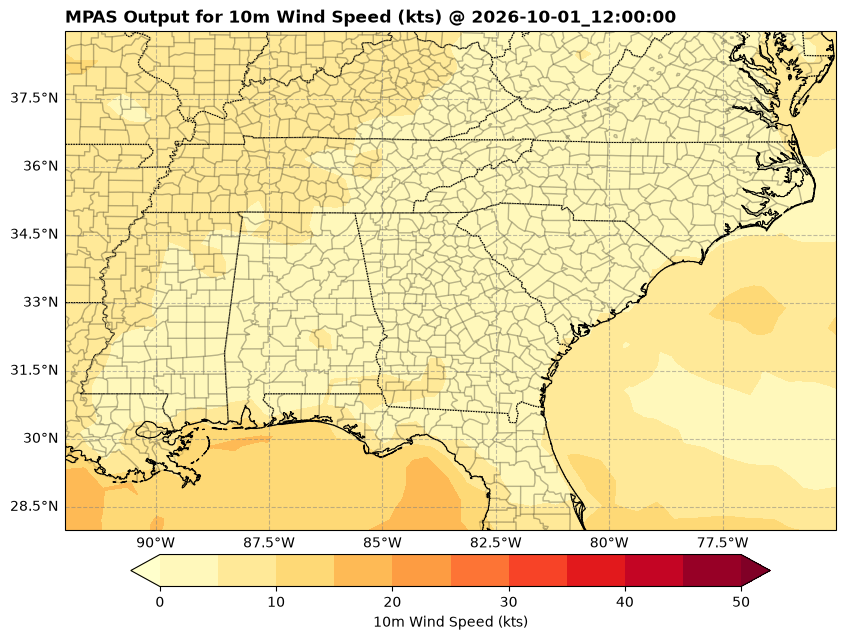

In [5]:
fig, ax = plt.subplots(figsize=(11, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent(extent, crs=ccrs.PlateCarree())

# Geographic features
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)
ax.add_feature(cfeature.STATES, linestyle=':', edgecolor='black', linewidth=0.7)
ax.add_feature(USCOUNTIES.with_scale('20m'), alpha=0.15)

# Triangulation plot
cf = ax.tricontourf(
    sub_lon, sub_lat, sub_data,
    levels=levels,
    cmap=cmap,
    extend='both',
    transform=ccrs.PlateCarree()
)

# Colorbar
cbar = plt.colorbar(cf, ax=ax, orientation='horizontal', pad=0.04, shrink=0.75)
cbar.set_label(var_label, fontsize=10)

# Titles & Gridlines
ax.set_title(f"MPAS Output for {var_label} @ {valid_time_str}", loc='left', fontweight='bold', fontsize=12)
gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False

plt.show()

### Challenge below: Using Scipy to grab the nearest value of a specific coordinate



In [6]:
from scipy.interpolate import griddata

# Sample point: Athens, GA
target_lat, target_lon = 33.95, -83.38

station_val = griddata(
    (lon_centers, lat_centers),
    (data.values if hasattr(data, 'values') else data),
    (target_lon, target_lat),
    method='linear'
)

print(f"Simulated {var_label} at Athens, GA: {station_val:.2f}")

Simulated 10m Wind Speed (kts) at Athens, GA: 2.88
